# From Words to Attention: Building a Transformer Block

## Project
Implement the core components of a language model in PyTorch: tokenization, embeddings, positional encoding, scaled attention, a causal mask, multi-head attention, and a transformer block. Inspect tensor shapes and the effect of masking. This is the first part of the learning path; wine reviews provide the example text.

Requirements: `torch` and `matplotlib`. The examples run on CPU or CUDA.

## Theoretical Framework: Transforming a Sequence with Attention

### Representing the problem
We treat text as an ordered sequence of discrete random variables $x_1,\ldots,x_T$, where each token belongs to a vocabulary $\mathcal V$ of size $V$. The model does not compute directly on symbols: a tokenizer assigns each token an index $i\in\{0,\ldots,V-1\}$, and an embedding matrix $E\in\mathbb R^{V\times d}$ maps that index to a vector $e_i=E[i]$. For a batch, we obtain a tensor $X\in\mathbb R^{B\times T\times d}$. A token index is categorical, not a measure of distance: the difference between indices 17 and 18 does not imply semantic similarity.

### From input to queries, keys, and values
Self-attention creates three learned views of the same representation: $Q=XW_Q$, $K=XW_K$, $V=XW_V$, where $W_Q,W_K\in\mathbb R^{d\times d_k}$ and $W_V\in\mathbb R^{d\times d_v}$. For token $i$, the scalar $q_i^\top k_j$ measures how useful information at position $j$ is to position $i$. Applying softmax over the key index $j$ gives attention weights $a_{ij}=\exp(s_{ij})/\sum_l\exp(s_{il})$. The output at position $i$ is $z_i=\sum_j a_{ij}v_j$: each position builds a contextual representation as a weighted sum of information from other positions.

The dot product can grow with dimensionality. If the components of Q and K are independent with mean 0 and variance 1, the variance of $q^\top k$ is proportional to $d_k$. Dividing by $\sqrt{d_k}$ brings the logits to a scale where softmax is less likely to saturate and gradients are less likely to vanish. This factor is not arbitrary; it follows from the variance of a sum of components.

### Masking, order, and causality
Without constraints, attention at each position can use every position in the sequence. An autoregressive model requires $p(x_t\mid x_{<t})$, so we define $M_{tj}=0$ for $j\le t$ and $M_{tj}=-\infty$ for $j>t$. In practice, a large negative value in the tensor dtype is used. Softmax then assigns zero weight to future positions. Masking is required by the prediction objective; it is not merely an implementation choice.

Self-attention without positional information is permutation-equivariant: permuting the input embeddings permutes the output in the same way, because all positions are processed by the same functions. Similarity alone cannot distinguish “the dog chases the cat” from “the cat chases the dog.” Adding a positional embedding $P$ to the input, $H^{(0)}=E[x]+P$, supplies order information. Sinusoidal encoding uses waves at different frequencies: $PE_{pos,2i}=\sin(pos/10000^{2i/d})$ and $PE_{pos,2i+1}=\cos(pos/10000^{2i/d})$. Learned positions and relative encodings (such as RoPE) are alternatives; they do not change the basic definition of attention.

### Multiple heads and the transformer layer
With $h$ heads, the model divides channels into subspaces and computes $head_r=Attention(XW^Q_r,XW^K_r,XW^V_r)$ in parallel. Concatenation and projection through $W^O$ combine these representations. The MLP acts independently at each position, but works together with attention: attention mixes information across positions, while the MLP transforms channel features. A residual connection $x+f(x)$ preserves an identity path, and LayerNorm controls activation scale. A typical pre-LN block is $u=x+MHA(LN(x))$, $y=u+MLP(LN(u))$.

For a sequence of length $T$, dimension $d$, and $h$ heads, the attention score matrices contain $hT^2$ elements per example. Attention costs $O(T^2d)$ computation and $O(hT^2)$ memory for the weights. Projections and the MLP cost $O(Td^2)$. As a result, the quadratic term can dominate for long sequences, even when the parameter count is unchanged.

### What this notebook derives
The following sections translate these equations into PyTorch tensors. Track the dimensions: batch, heads, query/key positions, and channels. A correct block preserves shape $(B,T,d)$, normalizes weights over the key axis, and assigns zero weight to causally disallowed connections.

## 1. Corpus and Tokenization
The full Wine Reviews dataset usually needs to be downloaded separately. To keep this notebook offline and self-contained, we use a small educational corpus. It is not statistically representative; you can replace it with a local CSV.

In [1]:
import math,re,torch
from torch import nn
import matplotlib.pyplot as plt
torch.manual_seed(42)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
reviews=["aromatic cherry and plum with a long finish","bright acidity balances ripe citrus fruit","dry wine with notes of pear and mineral","soft tannins frame dark berry and spice","fresh apple aroma with crisp acidity","rich oak vanilla and blackcurrant flavors","light bodied wine with floral notes","ripe peach and honey with a smooth finish","structured tannins and earthy cherry notes","zesty lemon aroma and clean mineral finish","bold dark fruit with pepper and toasted oak","delicate strawberry notes and lively acidity"]
def tokenize(s): return re.findall(r"[a-z]+|[^\w\s]",s.lower())
special=["<pad>","<unk>","<bos>","<eos>"]
vocab=special+sorted({t for s in reviews for t in tokenize(s)})
stoi={t:i for i,t in enumerate(vocab)}
ids=torch.tensor([[stoi.get(t,1) for t in tokenize(reviews[0])]],device=device)
embedding=nn.Embedding(len(vocab),16).to(device)
print("device",device,"vocabulary",len(vocab),"IDs",ids.shape,"embedding",embedding(ids).shape)

device cpu vocabulary 56 IDs torch.Size([1, 8]) embedding torch.Size([1, 8, 16])


## 2. Scaled Dot-Product Attention
For queries $Q$, keys $K$, and values $V$:

$$Attention(Q,K,V)=softmax(QK^T/\sqrt{d_k}+M)V.$$

$QK^T$ measures how well each query matches each key. Dividing by $\sqrt{d_k}$ stabilizes the scale of the logits. The mask $M$ adds a large negative value (theoretically $-\infty$) to disallowed connections.

In [2]:
def attention(q,k,v,mask=None):
    scores=q@k.transpose(-2,-1)/math.sqrt(q.size(-1))
    if mask is not None:scores=scores.masked_fill(~mask,torch.finfo(scores.dtype).min)
    weights=scores.softmax(-1)
    return weights@v,weights
B,T,dh=2,6,8
q=torch.randn(B,1,T,dh,device=device);k=torch.randn_like(q);v=torch.randn_like(q)
y,a=attention(q,k,v)
print("output",y.shape,"attention weights",a.shape,"softmax row sums",a.sum(-1)[0,0])

output torch.Size([2, 1, 6, 8]) attention weights torch.Size([2, 1, 6, 6]) softmax row sums tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


## 3. Causal Masking
GPT predicts $x_t$ only from $x_{<t}$. A lower-triangular mask allows keys $j\le t$ and blocks the future. In the boolean mask, `True` means that a position is allowed.

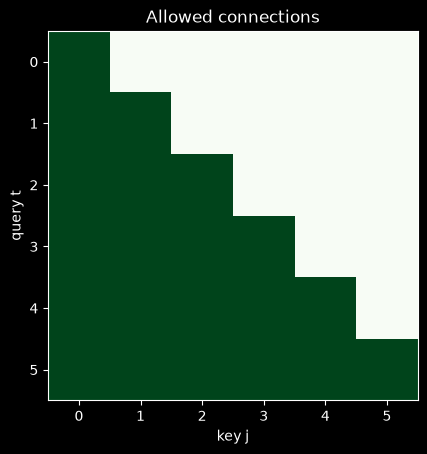

Maximum attention weight on future positions: 0.0


In [3]:
mask=torch.tril(torch.ones(T,T,dtype=torch.bool,device=device))
plt.imshow(mask.cpu(),cmap="Greens");plt.xlabel("key j");plt.ylabel("query t");plt.title("Allowed connections");plt.show()
_,aw=attention(q,k,v,mask)
print("Maximum attention weight on future positions:",aw.masked_select(~mask).max().item())

## 4. Multi-Head Attention
Each head has its own projections and can represent different relationships. The outputs are concatenated and projected: $MHA(X)=Concat(head_i)W^O$. Typically, $d_k=d_{model}/h$.

In [4]:
class MultiHeadAttention(nn.Module):
    def __init__(self,d_model,n_heads,dropout=0.):
        super().__init__(); assert d_model%n_heads==0
        self.h=n_heads;self.dh=d_model//n_heads
        self.qkv=nn.Linear(d_model,3*d_model);self.out=nn.Linear(d_model,d_model);self.drop=nn.Dropout(dropout)
    def forward(self,x,mask=None):
        B,T,C=x.shape;q,k,v=self.qkv(x).chunk(3,-1)
        def split(z):return z.view(B,T,self.h,self.dh).transpose(1,2)
        z,w=attention(split(q),split(k),split(v),mask)
        z=z.transpose(1,2).contiguous().view(B,T,C)
        return self.drop(self.out(z)),w
probe=torch.randn(2,7,32,device=device);mha=MultiHeadAttention(32,4).to(device)
y,w=mha(probe,torch.tril(torch.ones(7,7,dtype=torch.bool,device=device)))
print("input",probe.shape,"output",y.shape,"attention maps",w.shape)

input torch.Size([2, 7, 32]) output torch.Size([2, 7, 32]) attention maps torch.Size([2, 4, 7, 7])


## 5. Positional Encoding
Self-attention without order information is permutation-equivariant. The original Transformer's sinusoidal encoding is $PE_{pos,2i}=\sin(pos/10000^{2i/d})$ and $PE_{pos,2i+1}=\cos(pos/10000^{2i/d})$. GPT often learns positional embeddings; newer variants also use RoPE.

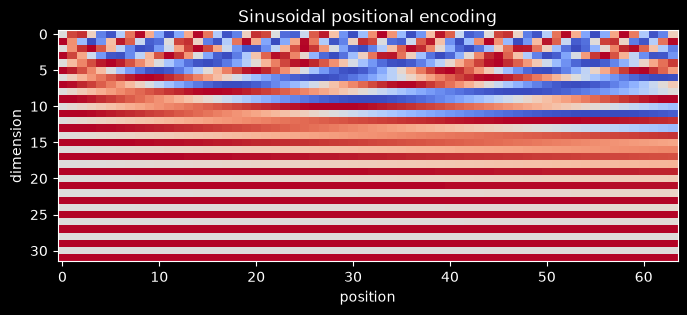

In [5]:
class SinusoidalPosition(nn.Module):
    def __init__(self,d,max_len=256):
        super().__init__();pos=torch.arange(max_len).unsqueeze(1)
        div=torch.exp(torch.arange(0,d,2)*(-math.log(10000.)/d))
        pe=torch.zeros(max_len,d);pe[:,0::2]=torch.sin(pos*div);pe[:,1::2]=torch.cos(pos*div[:pe[:,1::2].shape[1]])
        self.register_buffer("pe",pe[None])
    def forward(self,x):return x+self.pe[:,:x.size(1)].to(x.dtype)
pos=SinusoidalPosition(32,64).to(device)
plt.figure(figsize=(8,3));plt.imshow(pos.pe[0].cpu().T,aspect="auto",cmap="coolwarm");plt.xlabel("position");plt.ylabel("dimension");plt.title("Sinusoidal positional encoding");plt.show()

## 6. Decoder-Only Block
A common pre-LayerNorm variant has residual attention and an MLP: $X'=X+MHA(LN(X))$, $Y=X'+MLP(LN(X'))$. The MLP often expands the representation to $4d$. GELU adds nonlinearity, while residual connections help gradients flow.

In [6]:
class Block(nn.Module):
    def __init__(self,d,h,dropout=.1):
        super().__init__();self.ln1=nn.LayerNorm(d);self.attn=MultiHeadAttention(d,h,dropout);self.ln2=nn.LayerNorm(d)
        self.mlp=nn.Sequential(nn.Linear(d,4*d),nn.GELU(),nn.Linear(4*d,d),nn.Dropout(dropout))
    def forward(self,x,mask):
        a,w=self.attn(self.ln1(x),mask);x=x+a;return x+self.mlp(self.ln2(x)),w
block=Block(32,4).to(device);out,maps=block(probe,torch.tril(torch.ones(7,7,dtype=torch.bool,device=device)))
print("output",out.shape,"attention maps",maps.shape,"parameters",sum(p.numel() for p in block.parameters()))

output torch.Size([2, 7, 32]) attention maps torch.Size([2, 4, 7, 7]) parameters 12704


## 7. Complexity and Exercises
For sequence length $T$, standard attention costs $O(T^2d)$ computation and $O(T^2)$ memory per head.

1. Build a local mask where each token can see at most the previous 3 positions.
2. Change the number of heads while keeping $d_{model}$ fixed and inspect the dimensions.
3. Replace sinusoidal positions with a learned `nn.Embedding(max_len, d_model)`.
4. Explain why permuting the input without positional information also permutes the output.

## Summary
Q/K/V define a weighted aggregation of values. Scaling stabilizes softmax, a causal mask blocks the future, multiple heads combine different relationships, and positional encoding supplies order. A transformer block combines attention, an MLP, LayerNorm, and residual connections.

## Key Takeaways

- Self-attention forms learned queries, keys, and values, then uses $softmax(QK^T/\sqrt{d_k})$ to combine information across token positions.
- The causal mask enforces the autoregressive constraint: position $t$ cannot attend to positions $j>t$.
- Multi-head attention runs several attention projections in parallel; the MLP transforms each position independently, while attention mixes information across positions.
- Positional information is essential because self-attention alone does not encode token order. Sinusoidal, learned, and relative encodings are alternatives.
- Residual connections and LayerNorm help build deep, trainable transformer blocks.
- Standard attention has $O(T^2d)$ compute and $O(T^2)$ attention-weight memory, making long contexts expensive.